<a href="https://colab.research.google.com/github/Ariqq16/ML_2026/blob/main/JS07/JS07_Tugas_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   Sl_No  Customer Key  Avg_Credit_Limit  Total_Credit_Cards  \
0      1         87073            100000                   2   
1      2         38414             50000                   3   
2      3         17341             50000                   7   
3      4         40496             30000                   5   
4      5         47437            100000                   6   

   Total_visits_bank  Total_visits_online  Total_calls_made  
0                  1                    1                 0  
1                  0                   10                 9  
2                  1                    3                 4  
3                  1                    1                 4  
4                  0                   12                 3  


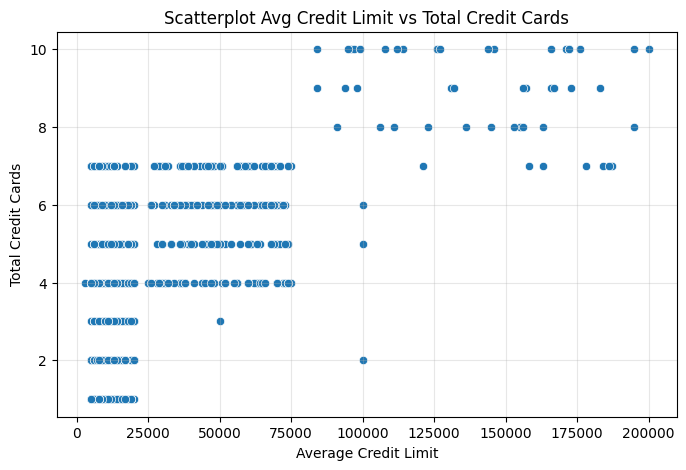

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/sample_data/CC_Customer_Dataset.csv')

print(df.head())

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards'
)

plt.title('Scatterplot Avg Credit Limit vs Total Credit Cards')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.grid(True, alpha=0.3)
plt.show()

In [2]:
korelasi = df[
    ['Avg_Credit_Limit', 'Total_Credit_Cards']
].corr()

print(korelasi)

print(
    "\nKoefisien korelasi:",
    df['Avg_Credit_Limit'].corr(
        df['Total_Credit_Cards']
    )
)

                    Avg_Credit_Limit  Total_Credit_Cards
Avg_Credit_Limit             1.00000             0.60886
Total_Credit_Cards           0.60886             1.00000

Koefisien korelasi: 0.6088604935524963


In [4]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

df = pd.read_csv('/content/sample_data/CC_Customer_Dataset.csv')

fitur = [
    'Avg_Credit_Limit',
    'Total_Credit_Cards',
    'Total_visits_bank',
    'Total_visits_online',
    'Total_calls_made'
]

X = df[fitur]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Ukuran dataset:", X_scaled.shape)

Ukuran dataset: (660, 5)


In [6]:
inertia = []

k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)

for k, nilai in zip(k_range, inertia):
    print(f"k = {k}, Inertia = {nilai:.2f}")

k = 1, Inertia = 3300.00
k = 2, Inertia = 2040.99
k = 3, Inertia = 933.04
k = 4, Inertia = 780.77
k = 5, Inertia = 704.48
k = 6, Inertia = 642.27
k = 7, Inertia = 599.93
k = 8, Inertia = 567.33
k = 9, Inertia = 542.25
k = 10, Inertia = 516.24


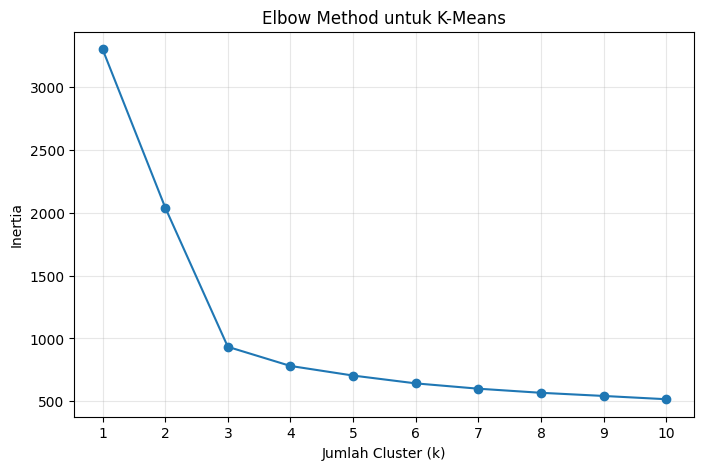

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_range),
    inertia,
    marker='o'
)

plt.title('Elbow Method untuk K-Means')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Inertia')
plt.xticks(list(k_range))
plt.grid(True, alpha=0.3)
plt.show()

Jumlah pelanggan setiap cluster:
Cluster
0    386
1     50
2    224
Name: count, dtype: int64


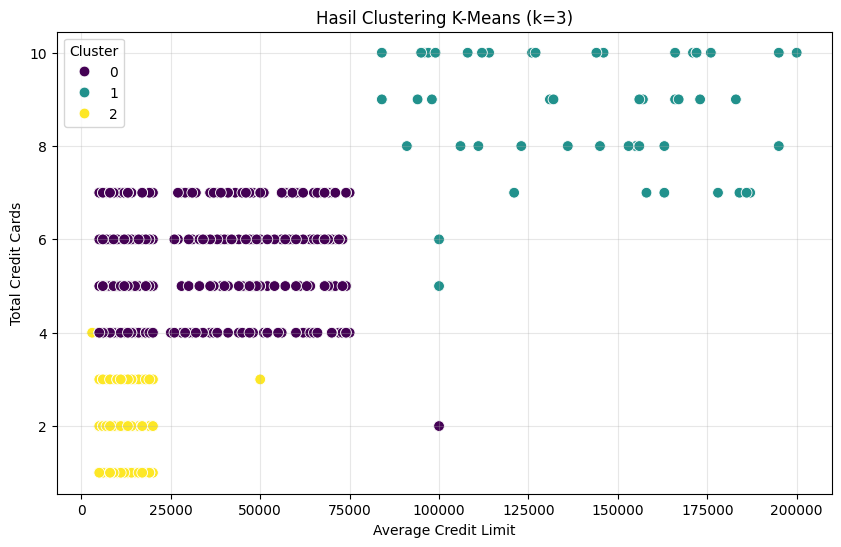

In [8]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print("Jumlah pelanggan setiap cluster:")
print(df['Cluster'].value_counts().sort_index())

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards',
    hue='Cluster',
    palette='viridis',
    s=60
)

plt.title('Hasil Clustering K-Means (k=3)')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.legend(title='Cluster')
plt.grid(True, alpha=0.3)
plt.show()

In [9]:
# Menghitung rata-rata fitur pada setiap cluster
profil_cluster = df.groupby('Cluster')[fitur].mean().round(2)

print("Profil rata-rata setiap cluster:")
print(profil_cluster)

Profil rata-rata setiap cluster:
         Avg_Credit_Limit  Total_Credit_Cards  Total_visits_bank  \
Cluster                                                            
0                33782.38                5.52               3.49   
1               141040.00                8.74               0.60   
2                12174.11                2.41               0.93   

         Total_visits_online  Total_calls_made  
Cluster                                         
0                       0.98              2.00  
1                      10.90              1.08  
2                       3.55              6.87  


In [10]:
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

# Fitur yang digunakan
fitur = [
    'Avg_Credit_Limit',
    'Total_Credit_Cards',
    'Total_visits_bank',
    'Total_visits_online',
    'Total_calls_made'
]

X = df[fitur]

# Standardisasi fitur
scaler_dbscan = StandardScaler()
X_scaled_dbscan = scaler_dbscan.fit_transform(X)

print("Jumlah data:", X_scaled_dbscan.shape[0])
print("Jumlah fitur:", X_scaled_dbscan.shape[1])

Jumlah data: 660
Jumlah fitur: 5


In [11]:
# DBSCAN
dbscan = DBSCAN(
    eps=1.0,
    min_samples=4
)

# clustering
df['Cluster_DBSCAN'] = dbscan.fit_predict(
    X_scaled_dbscan
)

# Menampilkan jumlah anggota setiap cluster
print("Jumlah anggota setiap cluster:")
print(df['Cluster_DBSCAN'].value_counts().sort_index())

Jumlah anggota setiap cluster:
Cluster_DBSCAN
-1     15
 0    608
 1     37
Name: count, dtype: int64


In [12]:
# Menghitung jumlah cluster, tidak termasuk noise
labels_dbscan = df['Cluster_DBSCAN'].values

jumlah_cluster = len(
    set(labels_dbscan) - {-1}
)

jumlah_noise = (labels_dbscan == -1).sum()

print("Jumlah cluster:", jumlah_cluster)
print("Jumlah data noise:", jumlah_noise)

Jumlah cluster: 2
Jumlah data noise: 15


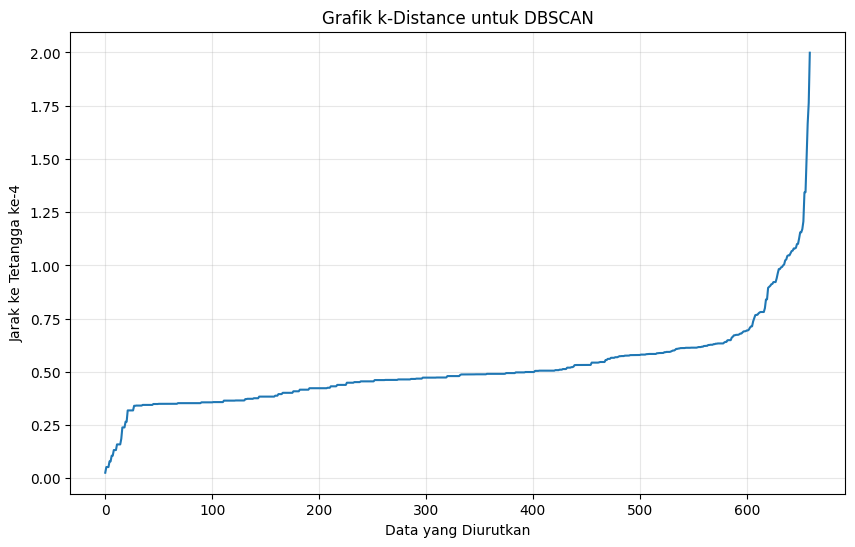

In [13]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.neighbors import NearestNeighbors

min_samples = 4

neighbors = NearestNeighbors(
    n_neighbors=min_samples
)

neighbors.fit(X_scaled_dbscan)

distances, indices = neighbors.kneighbors(
    X_scaled_dbscan
)

k_distances = distances[:, -1]

k_distances = np.sort(k_distances)

plt.figure(figsize=(10, 6))

plt.plot(k_distances)

plt.title('Grafik k-Distance untuk DBSCAN')
plt.xlabel('Data yang Diurutkan')
plt.ylabel('Jarak ke Tetangga ke-4')
plt.grid(True, alpha=0.3)

plt.show()

In [14]:
import pandas as pd

from sklearn.cluster import DBSCAN

hasil_dbscan = []

eps_values = [0.5, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2]
min_samples_values = [3, 4, 5, 6, 8]

for eps in eps_values:
    for min_samples in min_samples_values:

        model = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = model.fit_predict(X_scaled_dbscan)

        n_clusters = len(
            set(labels) - {-1}
        )

        n_noise = (labels == -1).sum()

        hasil_dbscan.append({
            'eps': eps,
            'min_samples': min_samples,
            'jumlah_cluster': n_clusters,
            'jumlah_noise': n_noise,
            'persentase_noise': round(
                n_noise / len(labels) * 100, 2
            )
        })

tabel_dbscan = pd.DataFrame(hasil_dbscan)

print(tabel_dbscan.to_string(index=False))

 eps  min_samples  jumlah_cluster  jumlah_noise  persentase_noise
 0.5            3              22           102             15.45
 0.5            4              22           141             21.36
 0.5            5              24           205             31.06
 0.5            6              21           281             42.58
 0.5            8              18           433             65.61
 0.7            3               3            46              6.97
 0.7            4               3            49              7.42
 0.7            5               1            58              8.79
 0.7            6               1            58              8.79
 0.7            8               1            64              9.70
 0.8            3               6            21              3.18
 0.8            4               4            28              4.24
 0.8            5               2            44              6.67
 0.8            6               2            48              7.27
 0.8      

In [15]:
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

labels_dbscan = df['Cluster_DBSCAN'].values

mask = labels_dbscan != -1

X_no_noise = X_scaled_dbscan[mask]
labels_no_noise = labels_dbscan[mask]

n_clusters = len(set(labels_no_noise))

print("Jumlah cluster:", n_clusters)
print("Jumlah noise:", (~mask).sum())
print("Jumlah data yang dievaluasi:", mask.sum())

if n_clusters >= 2 and len(X_no_noise) > n_clusters:

    silhouette = silhouette_score(
        X_no_noise,
        labels_no_noise
    )

    dbi = davies_bouldin_score(
        X_no_noise,
        labels_no_noise
    )

    print("\nSilhouette Score:", round(silhouette, 4))
    print("Davies-Bouldin Index:", round(dbi, 4))

else:
    print(
        "Metrik tidak dapat dihitung karena "
        "jumlah cluster tidak mencukupi."
    )

Jumlah cluster: 2
Jumlah noise: 15
Jumlah data yang dievaluasi: 645

Silhouette Score: 0.5716
Davies-Bouldin Index: 0.6054
